1. Etude du niveau de vie 
Nous avons cherché à pouvoir utiliser une api pour cette partie cependant le niveau le plus détaillé sur Melodi (API de l'INSEE) est le niveau communal. Nous nous voulons nous intéresser au niveau des quartiers (division IRIS). 

Nous comparons donc le niveau de vie médian par quartier IRIS à Saint-Ouen-sur-Seine entre 2018 (avant l'arrivée de la ligne 14) et 2021 en s'appuyant sur des briques déjà factorisées dans utils.py (DOSSIER_PROJET et _trouver_fichier pour localiser les fichiers, COL_IRIS et _normaliser_colonne_iris pour uniformiser la clé code_iris, et cadrer_carte pour le cadrage et le masquage des axes).

- Préparation géographique (iris.gpkg) : le fond IRIS est localisé via _trouver_fichier, normalisé sur code_iris (_normaliser_colonne_iris), formaté sur 9 caractères et filtré sur la commune 93070.

- Import et nettoyage Filosofi (2018 et 2021) : les fichiers Excel annuels sont repérés automatiquement (_trouver_excel_annee), lus avec skiprows=5, puis nettoyés (_preparer_filosofi) après détection automatique de la colonne de niveau de vie médian (_trouver_colonne_niveau_vie) et passage en numérique.

- Jointure et calcul d'évolution : les données 2018 et 2021 sont jointes aux contours IRIS sur code_iris, puis l'évolution relative est calculée en pourcentage entre les deux millésimes.

- Cartographie comparative : trois cartes sont affichées côte à côte avec cadrer_carte : 2018 et 2021 partagent la même échelle pour comparer les niveaux, tandis que l'évolution utilise une échelle divergente centrée sur 0 %.

-> Contours IRIS chargés via WFS IGN.


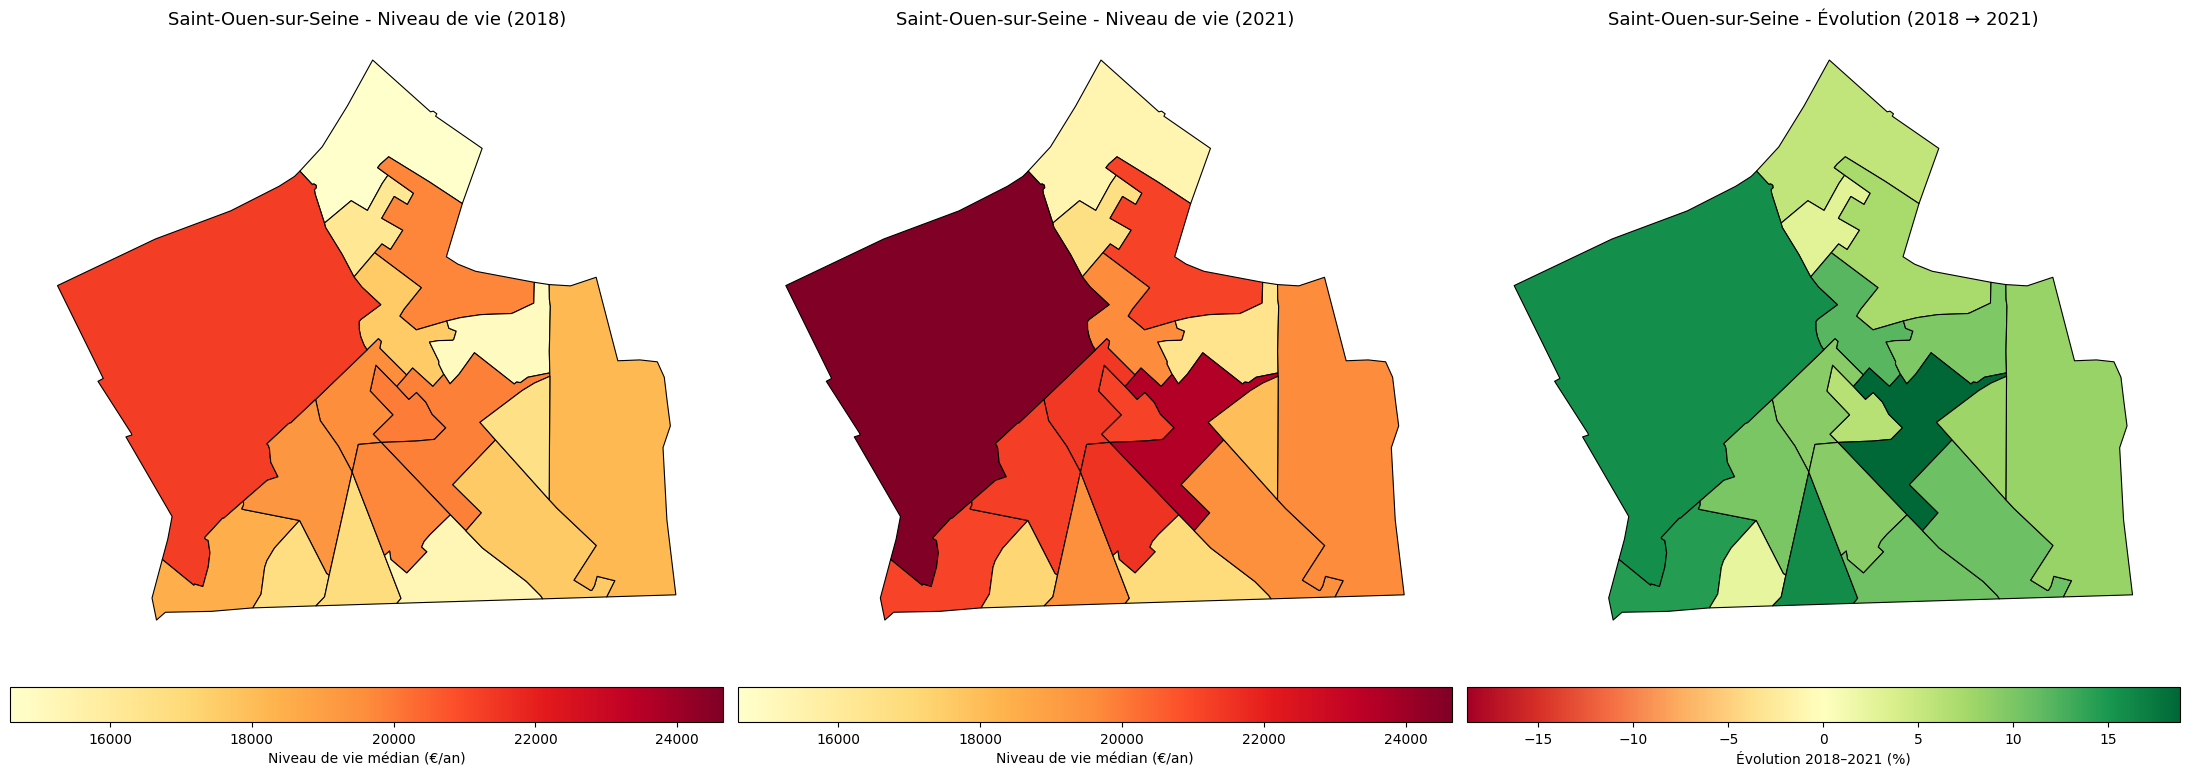

In [ ]:
from urllib.parse import urlencode
import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import requests

from utils import (
    COL_IRIS,
    DOSSIER_PROJET,
    _normaliser_colonne_iris,
    _trouver_fichier,
    cadrer_carte,
)

CODE_INSEE = "93070"


def _creer_session() -> requests.Session:
  session = requests.Session()
  session.headers.update(
      {"User-Agent": "Mozilla/5.0 (compatible; EnsaeGeoProject/1.0)"}
  )
  return session


SESSION = _creer_session()


def charger_iris_api(commune_prefix: str = CODE_INSEE) -> gpd.GeoDataFrame:
  # Récupère les contours IRIS via le WFS IGN.
  candidats_bbox = [
      "2.310,48.895,2.360,48.925,urn:ogc:def:crs:EPSG::4326",
      "48.895,2.310,48.925,2.360,urn:ogc:def:crs:EPSG::4326",
  ]

  for bbox in candidats_bbox:
    params = {
        "SERVICE": "WFS",
        "VERSION": "2.0.0",
        "REQUEST": "GetFeature",
        "TYPENAME": "STATISTICALUNITS.IRIS:contours_iris",
        "OUTPUTFORMAT": "application/json",
        "SRSNAME": "EPSG:4326",
        "COUNT": "200",
        "BBOX": bbox,
    }
    url = f"https://data.geopf.fr/wfs/ows?{urlencode(params)}"
    try:
      resp = SESSION.get(url, timeout=20)
      resp.raise_for_status()
      gdf = gpd.read_file(resp.text)
      if not gdf.empty:
        gdf_norm = _normaliser_colonne_iris(gdf)
        st_ouen = gdf_norm[
            gdf_norm[COL_IRIS]
            .astype(str)
            .str.strip()
            .str.startswith(commune_prefix)
        ].copy()
        if not st_ouen.empty:
          st_ouen[COL_IRIS] = (
              st_ouen[COL_IRIS].astype(str).str.strip().str.zfill(9)
          )
          print("-> Contours IRIS chargés via WFS IGN.")
          return st_ouen
    except Exception:
      continue

  raise RuntimeError(
      f"Impossible de charger les contours IRIS ({commune_prefix}) via le WFS IGN."
  )


def _trouver_excel_annee(annee: int, nom_prefere: str) -> pd.DataFrame:
  """Charge le fichier Excel Filosofi d'une année donnée via _trouver_fichier."""
  chemin = _trouver_fichier(nom_prefere, DOSSIER_PROJET)
  return pd.read_excel(chemin, skiprows=5)


def _trouver_colonne_niveau_vie(df: pd.DataFrame, col_iris: str) -> str:
  """Identifie la colonne du niveau de vie médian dans un DataFrame Filosofi."""
  for col in ("DISP_MED18", "DISP_MED21", "DISP_MED"):
    if col in df.columns:
      return col

  for col in df.columns:
    if col != col_iris and any(
        mot in str(col).upper() for mot in ("MED", "DISP")
    ):
      serie = pd.to_numeric(df[col], errors="coerce").dropna()
      if not serie.empty and 10000 <= serie.mean() <= 40000:
        return col

  for col in df.columns:
    if col != col_iris:
      serie = pd.to_numeric(df[col], errors="coerce").dropna()
      if not serie.empty and 15000 <= serie.mean() <= 35000:
        return col

  raise ValueError(
      "Impossible d'identifier la colonne de niveau de vie médian. Colonnes"
      f" : {list(df.columns)}"
  )


def _preparer_filosofi(df: pd.DataFrame, col_niv: str) -> pd.DataFrame:
  #Normalise l'identifiant IRIS sur 9 caractères et convertit la variable en numérique.
  if "IRIS" not in df.columns:
    raise KeyError("La colonne 'IRIS' est absente du DataFrame.")

  out = df[["IRIS", col_niv]].rename(columns={"IRIS": COL_IRIS}).copy()
  out[COL_IRIS] = (
      out[COL_IRIS].astype(str).str.split(".").str[0].str.strip().str.zfill(9)
  )
  out[col_niv] = pd.to_numeric(out[col_niv], errors="coerce")
  return out


st_ouen_iris = charger_iris_api(CODE_INSEE)

df_2018_raw = _trouver_excel_annee(2018, "BASE_TD_FILO_DISP_IRIS_2018.xlsx")
col_niv_2018 = _trouver_colonne_niveau_vie(df_2018_raw, "IRIS")
df_2018 = _preparer_filosofi(df_2018_raw, col_niv_2018)

df_2021_raw = _trouver_excel_annee(2021, "BASE_TD_FILO_IRIS_2021_DISP.xlsx")
col_niv_2021 = _trouver_colonne_niveau_vie(df_2021_raw, "IRIS")
df_2021 = _preparer_filosofi(df_2021_raw, col_niv_2021)

st_ouen_2018 = st_ouen_iris.merge(df_2018, on=COL_IRIS, how="inner")
st_ouen_2021 = st_ouen_iris.merge(df_2021, on=COL_IRIS, how="inner")


st_ouen_evol = st_ouen_iris.merge(
    df_2018.rename(columns={col_niv_2018: "niv_2018"}), on=COL_IRIS, how="inner"
).merge(
    df_2021.rename(columns={col_niv_2021: "niv_2021"}), on=COL_IRIS, how="inner"
)
st_ouen_evol["evol_pct"] = (
    (st_ouen_evol["niv_2021"] - st_ouen_evol["niv_2018"])
    / st_ouen_evol["niv_2018"]
* 100
)

vmin_niv = min(
    st_ouen_2018[col_niv_2018].min(), st_ouen_2021[col_niv_2021].min()
)
vmax_niv = max(
    st_ouen_2018[col_niv_2018].max(), st_ouen_2021[col_niv_2021].max()
)

max_abs_evol = max(
    abs(st_ouen_evol["evol_pct"].min()),
    abs(st_ouen_evol["evol_pct"].max()),
)
norm_evol = mcolors.TwoSlopeNorm(vmin=-max_abs_evol, vcenter=0, vmax=max_abs_evol)

fig, axes = plt.subplots(1, 3, figsize=(22, 8))

options_niv = {
    "cmap": "YlOrRd",
    "vmin": vmin_niv,
    "vmax": vmax_niv,
    "edgecolor": "black",
    "linewidth": 0.8,
    "legend": True,
    "missing_kwds": {"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    "legend_kwds": {
        "label": "Niveau de vie médian (€/an)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
}

st_ouen_2018.plot(ax=axes[0], column=col_niv_2018, **options_niv)
axes[0].set_title("Saint-Ouen-sur-Seine - Niveau de vie (2018)", fontsize=13)
cadrer_carte(axes[0], st_ouen_2018)

st_ouen_2021.plot(ax=axes[1], column=col_niv_2021, **options_niv)
axes[1].set_title("Saint-Ouen-sur-Seine - Niveau de vie (2021)", fontsize=13)
cadrer_carte(axes[1], st_ouen_2021)

st_ouen_evol.plot(
    ax=axes[2],
    column="evol_pct",
    cmap="RdYlGn",
    norm=norm_evol,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Évolution 2018–2021 (%)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
)
axes[2].set_title(
    "Saint-Ouen-sur-Seine - Évolution (2018 → 2021)", fontsize=13
)
cadrer_carte(axes[2], st_ouen_evol)

plt.tight_layout()
plt.show()

- Une hausse généralisée des niveaux de vie entre 2018 et 2021 : la carte d'évolution montre une progression sur l'ensemble des IRIS de Saint-Ouen-sur-Seine (environ +3 % à +18 %, sans recul marqué), ce qui traduit un enrichissement global ou une évolution favorable du revenu médian sur la période entourant l'arrivée de la ligne 14.   
- Une accentuation des écarts entre quartiers : alors que les IRIS au nord et au sud partent de niveaux plus modestes en 2018 (~15 000–16 000 €/an) et progressent plus modérément, le grand secteur à l'ouest et un secteur central/est affichent à la fois les plus fortes hausses relatives et les niveaux les plus élevés en 2021 (jusqu'à ~24 000 €/an et plus).
- Ce que cela suggère sur la gentrification : cette hausse plus rapide dans certains quartiers est cohérente avec une dynamique de gentrification sélective plutôt qu'uniforme, mais elle ne suffit pas à la prouver seule.   

2. Analyse détaillée du traitement des données et des indicateurs socio-économiques
- Ce bloc de code réalise l'ensemble du pipeline de préparation, de transformation et de calcul statistique nécessaire pour analyser les dynamiques socio-professionnelles à l'échelle des îlots regroupés pour l'information statistique (IRIS) de la commune de Saint-Ouen-sur-Seine. Le traitement s'articule autour des étapes clés suivantes :Standardisation et nettoyage géospatial (preparer_csp) :
- Cette fonction commence par identifier dynamiquement la colonne contenant les codes IRIS ou les identifiants territoriaux dans le DataFrame brut. Elle normalise ensuite ces identifiants en chaînes de caractères de 9 chiffres (grâce au remplissage de zéros à gauche avec zfill(9)), ce qui garantit une jointure spatiale rigoureuse et sans erreur avec les contours vectoriels de l'IGN. Enfin, elle convertit l'ensemble des variables statistiques en formats numériques tout en gérant proprement les valeurs manquantes ou aberrantes (errors='coerce').Extraction et calcul des indicateurs de structure (calcul_indicateurs) :Concentration des cadres (part_cadres) : La fonction recherche automatiquement la colonne correspondant aux cadres (groupe socioprofessionnel CS3 pour le recensement de 2011 ou les codes GSEC13 / GSEC13_23 pour la période récente) ainsi que la colonne représentant le total des actifs de 15 à 64 ans. Elle calcule ensuite la part relative des cadres au sein de la population active résidente sous forme de pourcentage, tout en évitant les divisions par zéro.Indice de mixité sociale (mixité_sociale) : Pour quantifier la diversité de la structure socioprofessionnelle de chaque IRIS, le script isole l'ensemble des catégories (de CS1 à CS6 ou l'équivalent GSEC). Il applique ensuite la formule mathématique de l'entropie de Shannon, mesurant ainsi l'équilibre de la répartition des actifs entre les différentes catégories. Plus l'indice est élevé, plus le quartier présente une mixité socioprofessionnelle forte ; un indice faible indique au contraire la domination d'une seule catégorie.Harmonisation cartographique et visualisation comparative :
- Après avoir fusionné les indicateurs calculés avec les données géographiques (st_ouen_iris), le code extrait les bornes minimales et maximales globales (vmin / vmax) pour chaque indicateur. Cela permet d'uniformiser strictement les échelles de couleur entre les deux années (2011 et 2021/2022). Le script génère enfin une figure composée de quatre cartes comparatives facilitant l'analyse visuelle des évolutions territoriales, telles que les processus de gentrification ou les variations de la mixité sociale au fil du temps.

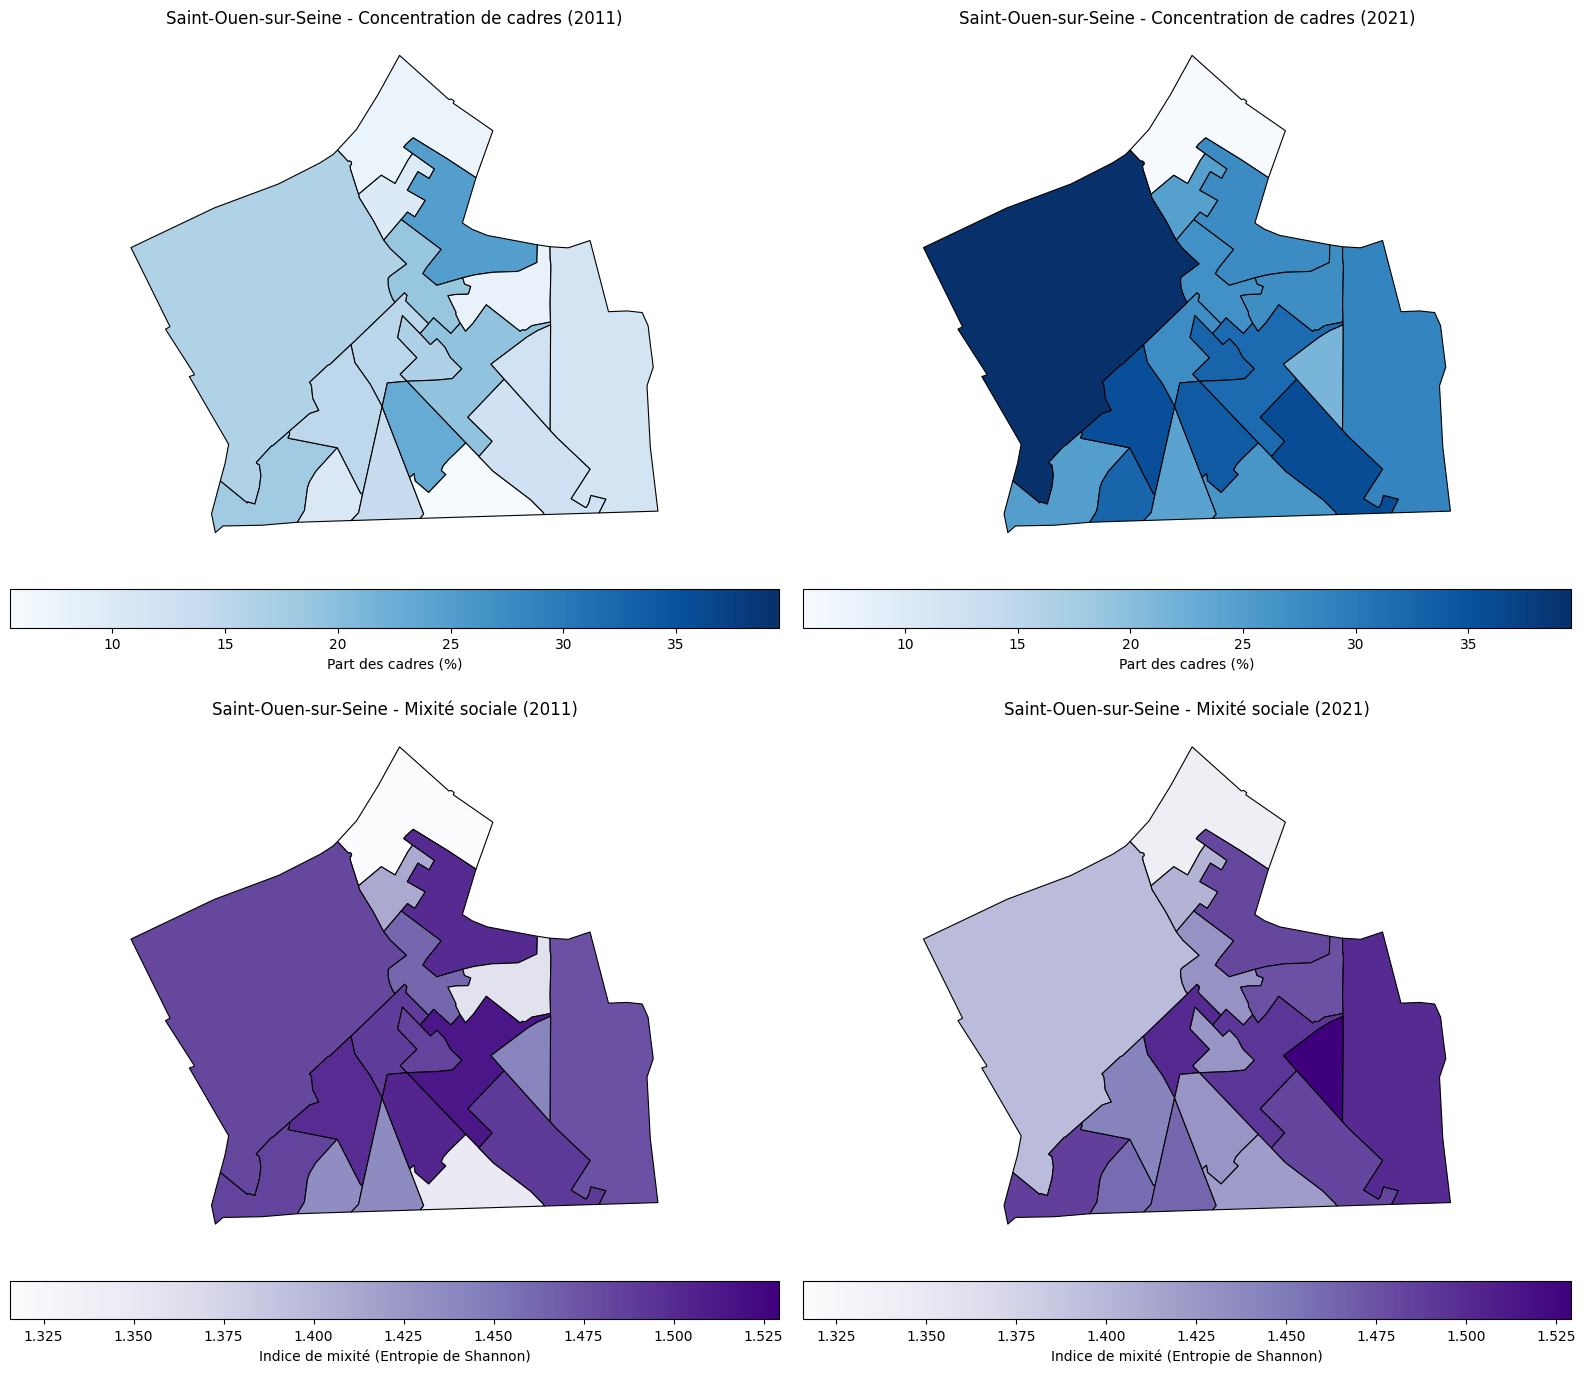

In [17]:
file_2011 = _trouver_fichier("base-ic-activite-residents-2011.xls", DOSSIER_PROJET)
file_2021 = _trouver_fichier(
    "base-ic-activite-residents-2022.xlsx", DOSSIER_PROJET
)

df_2011 = pd.read_excel(file_2011, skiprows=5)
df_2021 = pd.read_excel(file_2021, skiprows=5)

def preparer_csp(df: pd.DataFrame) -> pd.DataFrame:
  col_iris_src = next(
      (
          c
          for c in df.columns
          if "IRIS" in str(c).upper() or "CODE" in str(c).upper()
      ),
      df.columns[0],
  )
  out = df.copy()
  out[COL_IRIS] = (
      out[col_iris_src].astype(str).str.split(".").str[0].str.strip().str.zfill(9)
  )
  cols_num = {
      c: pd.to_numeric(out[c], errors="coerce") for c in out.columns if c != COL_IRIS
  }
  return pd.concat(
      [out[[COL_IRIS]], pd.DataFrame(cols_num, index=out.index)], axis=1
  )

def calcul_indicateurs(df: pd.DataFrame, label_annee: str = "") -> pd.DataFrame:
  col_cadres = next(
      (
          c
          for c in df.columns
          if any(
              k in str(c).upper()
              for k in ("C11_ACT1564_CS3", "CS3", "GSEC13_23", "GSEC13")
          )
          and "ACT1564" in str(c).upper()
      ),
      None,
  )

  col_total = next(
      (
          c
          for c in df.columns
          if str(c).upper().startswith("C")
          and "ACT1564" in str(c).upper()
          and not any(x in str(c).upper() for x in ("CS", "GSEC", "_H", "_F", "STAT"))
      ),
      None,
  )
  if col_total is None:
    col_total = next(
        (
            c
            for c in df.columns
            if "ACT1564" in str(c).upper()
            and not any(
                x in str(c).upper() for x in ("CS", "GSEC", "_H", "_F", "STAT")
            )
        ),
        None,
    )

  if col_cadres is None or col_total is None:
    raise ValueError(
        f"[{label_annee}] Colonnes non trouvées. Cadres={col_cadres},"
        f" Total={col_total}."
    )

  part_cadres = (df[col_cadres] / df[col_total].replace(0, np.nan)) * 100

  gsec_codes = (
      "GSEC11_21",
      "GSEC12_22",
      "GSEC13_23",
      "GSEC14_24",
      "GSEC15_25",
      "GSEC16_26",
  )
  cols_csp = [
      c
      for c in df.columns
      if any(g in str(c).upper() for g in gsec_codes)
      and "ACT1564" in str(c).upper()
  ]
  if not cols_csp:
    cs_codes = ("CS1", "CS2", "CS3", "CS4", "CS5", "CS6")
    cols_csp = [
        c
        for c in df.columns
        if any(str(c).upper().endswith(k) for k in cs_codes)
        and "ACT1564" in str(c).upper()
    ]

  if len(cols_csp) >= 2:
    somme_csp = df[cols_csp].sum(axis=1).replace(0, np.nan)
    shannon = pd.Series(0.0, index=df.index)
    for c in cols_csp:
      p_i = (df[c] / somme_csp).clip(lower=0)
      masque = p_i > 0
      shannon.loc[masque] -= p_i.loc[masque] * np.log(p_i.loc[masque])
    mixite = shannon
  else:
    mixite = pd.Series(np.nan, index=df.index)

  return pd.concat(
      [
          df.copy(),
          pd.DataFrame(
              {"part_cadres": part_cadres, "mixité_sociale": mixite},
              index=df.index,
          ),
      ],
      axis=1,
  )


df_2011 = calcul_indicateurs(preparer_csp(df_2011), "2011")
df_2021 = calcul_indicateurs(preparer_csp(df_2021), "2021")

st_ouen_2011_csp = st_ouen_iris.merge(df_2011, on=COL_IRIS, how="inner")
st_ouen_2021_csp = st_ouen_iris.merge(df_2021, on=COL_IRIS, how="inner")

vmin_cadres = min(
    st_ouen_2011_csp["part_cadres"].min(), st_ouen_2021_csp["part_cadres"].min()
)
vmax_cadres = max(
    st_ouen_2011_csp["part_cadres"].max(), st_ouen_2021_csp["part_cadres"].max()
)

vmin_shannon = min(
    st_ouen_2011_csp["mixité_sociale"].min(),
    st_ouen_2021_csp["mixité_sociale"].min(),
)
vmax_shannon = max(
    st_ouen_2011_csp["mixité_sociale"].max(),
    st_ouen_2021_csp["mixité_sociale"].max(),
)


fig, axes = plt.subplots(2, 2, figsize=(16, 14))

cartes = [
    (
        axes[0, 0],
        st_ouen_2011_csp,
        "part_cadres",
        "Blues",
        vmin_cadres,
        vmax_cadres,
        "Part des cadres (%)",
        "Saint-Ouen-sur-Seine - Concentration de cadres (2011)",
    ),
    (
        axes[0, 1],
        st_ouen_2021_csp,
        "part_cadres",
        "Blues",
        vmin_cadres,
        vmax_cadres,
        "Part des cadres (%)",
        "Saint-Ouen-sur-Seine - Concentration de cadres (2021)",
    ),
    (
        axes[1, 0],
        st_ouen_2011_csp,
        "mixité_sociale",
        "Purples",
        vmin_shannon,
        vmax_shannon,
        "Indice de mixité (Entropie de Shannon)",
        "Saint-Ouen-sur-Seine - Mixité sociale (2011)",
    ),
    (
        axes[1, 1],
        st_ouen_2021_csp,
        "mixité_sociale",
        "Purples",
        vmin_shannon,
        vmax_shannon,
        "Indice de mixité (Entropie de Shannon)",
        "Saint-Ouen-sur-Seine - Mixité sociale (2021)",
    ),
]

for ax, gdf_plot, col, cmap, vmin, vmax, label, titre in cartes:
  gdf_plot.plot(
      ax=ax,
      column=col,
      cmap=cmap,
      vmin=vmin,
      vmax=vmax,
      edgecolor="black",
      linewidth=0.8,
      legend=True,
      missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
      legend_kwds={"label": label, "orientation": "horizontal", "pad": 0.05},
  )
  ax.set_title(titre, fontsize=12)
  cadrer_carte(ax, gdf_plot)

plt.tight_layout()
plt.show()

L'analyse croisée des cartes de concentration des cadres et de l'indice de mixité sociale de Shannon révèle de manière saisissante les transformations profondes à l'œuvre à Saint-Ouen-sur-Seine entre 2011 et 2021. Loin d'être de simples variations statistiques, ces représentations spatiales matérialisent la gentrification massive et rapide de cette ancienne commune ouvrière de la petite couronne parisienne.En examinant la part des cadres, on observe un basculement visuel radical. Alors qu'en 2011 les teintes claires dominaient, montrant une proportion d'actifs cadres rarement supérieure à 20 ou 25 % hormis sur de rares secteurs, la carte de 2021 s'assombrit de manière générale. La commune tout entière est traversée par une vague de gentrification, avec des poches dépassant les 35 % de cadres. Cette diffusion n'est plus cantonnée à quelques rues isolées : elle est puissamment portée par les grands projets de renouvellement urbain, à l'instar de l'écoquartier des Docks sur les anciennes friches industrielles le long de la Seine, ainsi que par l'effet d'attractivité des nouvelles infrastructures de transport lourd comme le prolongement de la ligne 14 du métro.   Parallèlement, l'indice d'entropie de Shannon, qui mesure l'équilibre et la diversité de la répartition de l'ensemble des catégories socio-professionnelles, met en lumière une recomposition complexe des équilibres internes de la ville. Les variations de cet indice traduisent la transition des quartiers populaires historiques vers des profils sociologiques modifiés. Si l'arrivée de nouvelles populations engendre une mixité temporaire ou de transition dans certains îlots, elle porte également en germe le risque d'une homogénéisation par le haut et d'un phénomène d'éviction progressive des ménages les plus modestes face à la forte pression foncière et immobilière.   En somme, Saint-Ouen s'affirme à travers ces cartes comme l'archétype des mutations métropolitaines franciliennes. La commune joue pleinement son rôle de territoire de report résidentiel pour les cadres et les classes moyennes supérieures en quête de logements plus accessibles tout en restant arrimés à Paris, redessinant durablement le paysage social et urbain local.

3.Analyse spatiale de l'évolution des ménages d'une personne et des couples sans enfant à Saint-Ouen-sur-Seine (2011–2022)

- Ce script Python réalise l'ensemble de la chaîne de traitement, d'analyse statistique et de cartographie géospatiale pour étudier l'évolution de la structure des ménages à Saint-Ouen-sur-Seine entre 2011 et 2022, en s'appuyant sur les bases de données IRIS « Couples - Familles - Ménages » de l'INSEE.

- Le script récupère d'abord les fichiers Excel correspondants aux deux millésimes (2011 et 2022) via la fonction _trouver_fichier et charge les tableaux en ignorant les cinq premières lignes d'en-tête et de métadonnées (pd.read_excel(..., skiprows=5)).

- La fonction preparer_cfm détecte ensuite dynamiquement la colonne contenant les codes IRIS ou les identifiants territoriaux, standardise ces identifiants en chaînes de caractères de neuf chiffres (zfill(9)) pour garantir une jointure spatiale rigoureuse avec les contours géographiques de l'IGN, et convertit l'ensemble des variables statistiques au format numérique.

- La fonction calcul_indicateur_menages_cibles isole pour chaque millésime le total des ménages (_MEN), les ménages d'une personne (_MENPSEUL) et les couples sans enfant (_MENCOUPSENF), puis additionne les effectifs de ces deux catégories cibles pour calculer leur part en pourcentage par rapport au nombre total de ménages par îlot IRIS.

- Les indicateurs calculés pour 2011 et 2022 sont fusionnés successivement avec le fonds de carte vectoriel de Saint-Ouen (st_ouen_iris) à l'aide de jointures à gauche (how='left'), permettant au script de calculer directement l'écart absolu en points de pourcentage entre les deux dates (evol_pts).

- Enfin, le code extrait les bornes minimales et maximales globales pour uniformiser les échelles de couleur (vmin et vmax) et génère une figure composée de trois cartes comparatives : les deux premières affichent la répartition de ces ménages en 2011 et 2022 via une palette orangée homogène, tandis que la troisième utilise une palette divergente centrée sur zéro (RdBu_r) pour mettre en valeur les hausses et les baisses territoriales au fil de la décennie.

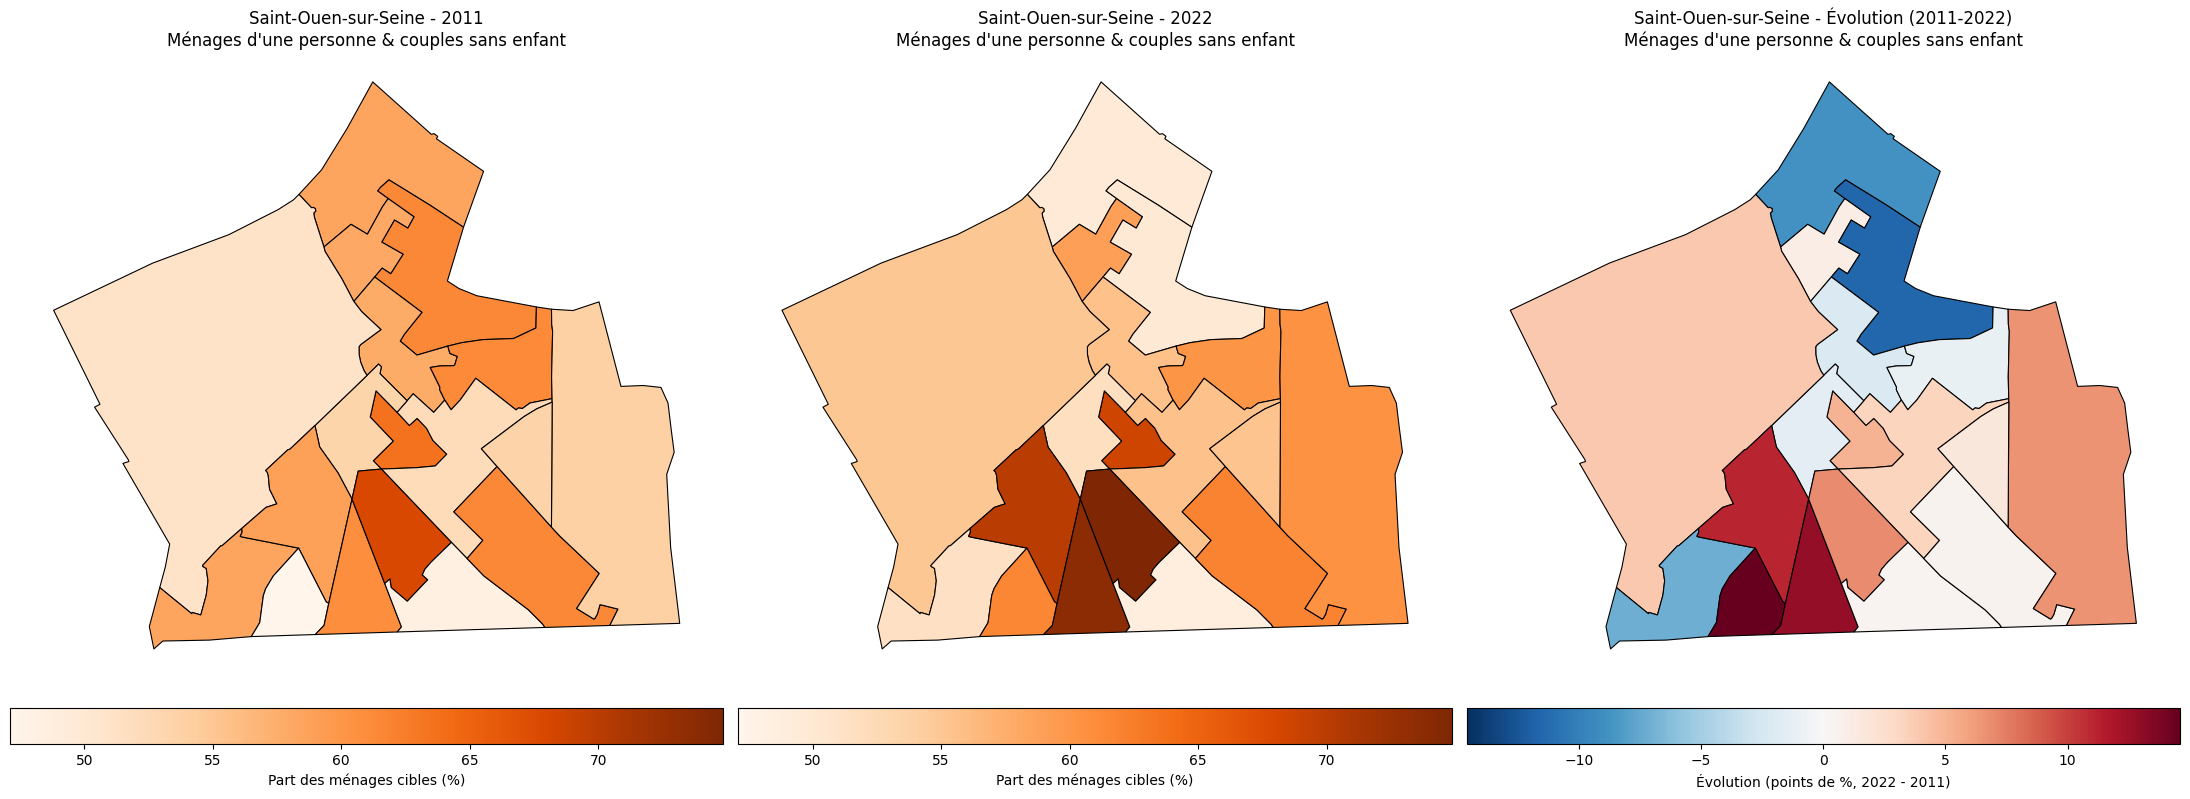

In [22]:
file_cfm_2011 = _trouver_fichier(
    "base-ic-couples-familles-menages-2011.xls", DOSSIER_PROJET
)
file_cfm_2022 = _trouver_fichier(
    "base-ic-couples-familles-menages-2022.xlsx", DOSSIER_PROJET
)

df_2011 = pd.read_excel(file_cfm_2011, skiprows=5)
df_2022 = pd.read_excel(file_cfm_2022, skiprows=5)


def preparer_cfm(df: pd.DataFrame) -> pd.DataFrame:
  col_iris_src = next(
      (
          c
          for c in df.columns
          if "IRIS" in str(c).upper() or "CODE" in str(c).upper()
      ),
      df.columns[0],
  )
  out = df.copy()
  out[COL_IRIS] = (
      out[col_iris_src].astype(str).str.split(".").str[0].str.strip().str.zfill(9)
  )
  cols_num = {
      c: pd.to_numeric(out[c], errors="coerce") for c in out.columns if c != COL_IRIS
  }
  return pd.concat(
      [out[[COL_IRIS]], pd.DataFrame(cols_num, index=out.index)], axis=1
  )


def calcul_indicateur_menages_cibles(
    df: pd.DataFrame, prefixe_annee: str
) -> pd.DataFrame:
 
  col_men = f"{prefixe_annee}_MEN"
  col_seuls = f"{prefixe_annee}_MENPSEUL"
  col_couples = f"{prefixe_annee}_MENCOUPSENF"

  # Vérification de sécurité des colonnes
  for c in [col_men, col_seuls, col_couples]:
    if c not in df.columns:
      raise KeyError(
          f"La colonne attendue '{c}' est introuvable dans le DataFrame."
      )

  nb_cible = df[col_seuls].fillna(0) + df[col_couples].fillna(0)
  nb_total = df[col_men].replace(0, np.nan)
  part_cible = (nb_cible / nb_total) * 100

  return pd.DataFrame(
      {
          COL_IRIS: df[COL_IRIS],
          "nb_cible": nb_cible,
          "nb_men_total": df[col_men],
          "part_cible_pct": part_cible,
      }
  )

ind_2011 = calcul_indicateur_menages_cibles(preparer_cfm(df_2011), "C11")
ind_2022 = calcul_indicateur_menages_cibles(preparer_cfm(df_2022), "C22")


evol_iris = (
    st_ouen_iris[["geometry", COL_IRIS]]
    .merge(
        ind_2011[[COL_IRIS, "nb_cible", "part_cible_pct"]].rename(
            columns={"nb_cible": "nb_2011", "part_cible_pct": "part_2011"}
        ),
        on=COL_IRIS,
        how="left",
    )
    .merge(
        ind_2022[[COL_IRIS, "nb_cible", "part_cible_pct"]].rename(
            columns={"nb_cible": "nb_2022", "part_cible_pct": "part_2022"}
        ),
        on=COL_IRIS,
        how="left",
    )
)

evol_iris["evol_pts"] = evol_iris["part_2022"] - evol_iris["part_2011"]

vals_parts = pd.concat(
    [evol_iris["part_2011"], evol_iris["part_2022"]], ignore_index=True
).dropna()
vmin_part = float(vals_parts.min()) if not vals_parts.empty else 0.0
vmax_part = float(vals_parts.max()) if not vals_parts.empty else 10.0
if vmin_part == vmax_part:
  vmax_part = vmin_part + 1.0

vmax_evol = np.nanmax(np.abs(evol_iris["evol_pts"]))
vmax_evol = float(vmax_evol) if pd.notna(vmax_evol) and vmax_evol > 0 else 5.0

fig, axes = plt.subplots(1, 3, figsize=(22, 8))

options_part = {
    "cmap": "Oranges",
    "vmin": vmin_part,
    "vmax": vmax_part,
    "edgecolor": "black",
    "linewidth": 0.8,
    "legend": True,
    "missing_kwds": {"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    "legend_kwds": {
        "label": "Part des ménages cibles (%)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
}

evol_iris.plot(ax=axes[0], column="part_2011", **options_part)
axes[0].set_title(
    "Saint-Ouen-sur-Seine - 2011\nMénages d'une personne & couples sans"
    " enfant",
    fontsize=12,
)
cadrer_carte(axes[0], evol_iris)

evol_iris.plot(ax=axes[1], column="part_2022", **options_part)
axes[1].set_title(
    "Saint-Ouen-sur-Seine - 2022\nMénages d'une personne & couples sans"
    " enfant",
    fontsize=12,
)
cadrer_carte(axes[1], evol_iris)

evol_iris.plot(
    ax=axes[2],
    column="evol_pts",
    cmap="RdBu_r",
    vmin=-vmax_evol,
    vmax=vmax_evol,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Évolution (points de %, 2022 - 2011)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[2].set_title(
    "Saint-Ouen-sur-Seine - Évolution (2011-2022)\nMénages d'une personne &"
    " couples sans enfant",
    fontsize=12,
)
cadrer_carte(axes[2], evol_iris)

plt.tight_layout()
plt.show()

L'analyse de ces cartes consacrées à la part des ménages d'une personne et des couples sans enfant apporte un éclairage décisif sur la géographie intime de la gentrification à Saint-Ouen-sur-Seine entre 2011 et 2022. Contrairement aux familles avec enfants, souvent plus ancrées dans les parcs sociaux ou les logements familiaux traditionnels, ces ménages constitués de personnes seules et de couples sans enfant (qui incluent une grande part de jeunes actifs, d'étudiants et de cadres célibataires) constituent la cible privilégiée des programmes immobiliers récents et des opérations de promotion privée.   
En observant les états de 2011 et de 2022, on constate que ces ménages représentent déjà une part très importante de la population audonienne, oscillant généralement entre 50 % et plus de 70 % des ménages totaux selon les îlots. Cependant, la structure spatiale de cette concentration se modifie profondément au cours de la décennie. En 2011, les zones aux proportions élevées étaient réparties de manière plus diffuse, tandis qu'en 2022, un pôle de concentration très dense s'affirme de manière spectaculaire dans la moitié sud et sud-ouest de la commune, atteignant les teintes les plus foncées de l'échelle.   
La carte de droite, qui mesure l'évolution en points de pourcentage entre 2011 et 2022, met en évidence la nature exacte de cette mutation territoriale. Elle révèle une opposition saisissante entre le nord de la ville, où la part de ces ménages a plutôt stagné ou régressé (marqué par les teintes bleues affichant des variations négatives allant jusqu'à -10 points), et le sud/sud-ouest, qui enregistre des hausses fulgurantes (teintes bordeaux dépassant les +10 points).   
Cette forte augmentation dans le secteur sud correspond précisément à la concrétisation des grands projets d'aménagement urbain, et en premier lieu l'écoquartier des Docks de Saint-Ouen érigé sur d'anciennes friches industrielles en bord de Seine, ainsi que l'effet d'attractivité des nouvelles connexions de transports. Ces nouveaux espaces résidentiels agissent comme des aimants pour de jeunes ménages sans enfants et des actifs parisiens en quête de décohabitation ou d'accession à la propriété, redessinant en profondeur le profil sociodémographique de la ville et consacrant la réussite spatiale des politiques de renouvellement urbain métropolitain.

4.Cartographie de l'évolution des familles monoparentales et nombreuses à Saint-Ouen-sur-Seine (2011-2022)

Nous récupérons d'abord les contours des IRIS de Saint-Ouen-sur-Seine (code INSEE 93070) via le service WFS de l'IGN, en testant deux ordres de coordonnées pour la requête par emprise, puis nous les filtrons sur le préfixe 93070 et mettons les codes sur 9 caractères. Nous lisons ensuite les bases INSEE « Couples, familles, ménages » de 2011 et 2022 avec pd.read_excel(skiprows=5).

La fonction preparer_cfm harmonise le code IRIS, en supprimant le suffixe décimal parfois ajouté par pandas, et convertit toutes les autres colonnes en numérique avec pd.to_numeric(errors="coerce"), ce qui transforme les valeurs non numériques en NaN.

La fonction calcul_indicateur_familles_cibles calcule ensuite, pour chaque millésime, l'effectif des ménages monoparentaux (C{an}_MENFAMMONO) et celui des familles nombreuses, dont nous détectons la colonne par recherche de motifs (FAM3P, FAM4P, MENFAM3P). Nous additionnons ces deux effectifs et les rapportons au total des ménages (C{an}_MEN), en remplaçant les zéros du dénominateur par NaN. Nous fusionnons les deux années aux géométries par merge(how="left") sur le code IRIS, puis nous calculons l'évolution en points de pourcentage (part_2022 - part_2011).

Enfin, nous traçons trois cartes geopandas côte à côte. Les cartes 2011 et 2022 partagent la même échelle Oranges (bornes communes) pour être comparables, et la carte d'évolution utilise la palette divergente RdBu_r, centrée sur zéro grâce à des bornes symétriques. Les IRIS sans données apparaissent en gris hachuré.

Notre indicateur présente trois limites : il additionne deux populations qui se recoupent, il est rapporté à l'ensemble des ménages plutôt qu'aux familles, et le découpage des IRIS a changé entre 2011 et 2022, ce qui impose de la prudence dans la comparaison zone par zone. Il faut aussi vérifier que la colonne des familles nombreuses a bien été trouvée, sinon seuls les monoparentaux sont comptés.

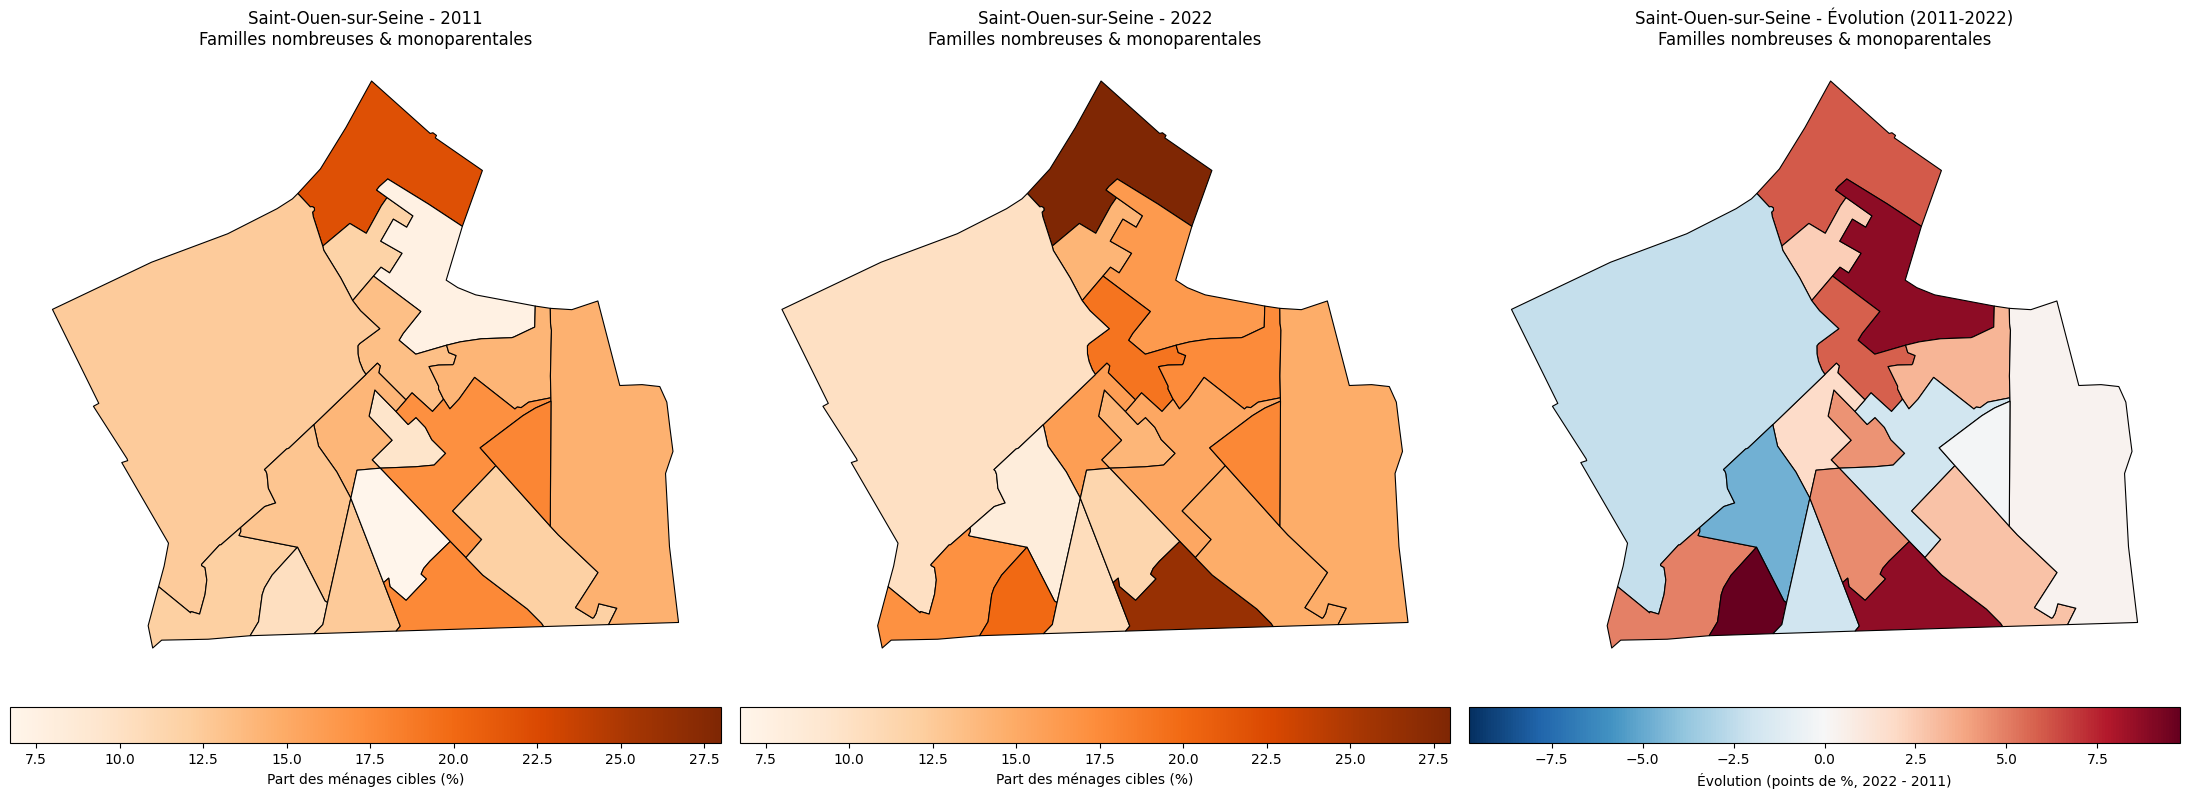

In [25]:
st_ouen_iris = charger_iris_api(CODE_INSEE)

file_cfm_2011 = _trouver_fichier(
    "base-ic-couples-familles-menages-2011.xls", DOSSIER_PROJET
)
file_cfm_2022 = _trouver_fichier(
    "base-ic-couples-familles-menages-2022.xlsx", DOSSIER_PROJET
)

df_2011 = pd.read_excel(file_cfm_2011, skiprows=5)
df_2022 = pd.read_excel(file_cfm_2022, skiprows=5)


# --- 2. FONCTIONS DE PRÉPARATION ET CALCUL ---
def preparer_cfm(df: pd.DataFrame) -> pd.DataFrame:
  col_iris_src = next(
      (
          c
          for c in df.columns
          if "IRIS" in str(c).upper() or "CODE" in str(c).upper()
      ),
      df.columns[0],
  )
  out = df.copy()
  out[COL_IRIS] = (
      out[col_iris_src].astype(str).str.split(".").str[0].str.strip().str.zfill(9)
  )
  cols_num = {
      c: pd.to_numeric(out[c], errors="coerce") for c in out.columns if c != COL_IRIS
  }
  return pd.concat(
      [out[[COL_IRIS]], pd.DataFrame(cols_num, index=out.index)], axis=1
  )


def calcul_indicateur_familles_cibles(
    df: pd.DataFrame, prefixe_annee: str
) -> pd.DataFrame:
  """Calcule l'effectif et la part (%) des familles nombreuses (3+ enfants)

  et des ménages monoparentaux à partir des nomenclatures officielles.
  """
  col_men_total = f"{prefixe_annee}_MEN"
  col_mono = f"{prefixe_annee}_MENFAMMONO"

  # Recherche dynamique de la colonne correspondant aux familles nombreuses (3+ enfants)
  col_fam3p = next(
      (
          c
          for c in df.columns
          if prefixe_annee in c
          and any(k in c.upper() for k in ("FAM3P", "FAM4P", "MENFAM3P"))
      ),
      None,
  )

  for c in [col_men_total, col_mono]:
    if c not in df.columns:
      raise KeyError(f"La colonne attendue '{c}' est introuvable.")

  eff_mono = df[col_mono].fillna(0)
  eff_nombreuses = df[col_fam3p].fillna(0) if col_fam3p else 0.0

  # Cible combinée (familles nombreuses + monoparentales)
  nb_cible = eff_mono + eff_nombreuses
  nb_total = df[col_men_total].replace(0, np.nan)
  part_cible = (nb_cible / nb_total) * 100

  return pd.DataFrame(
      {
          COL_IRIS: df[COL_IRIS],
          "nb_cible": nb_cible,
          "nb_men_total": df[col_men_total],
          "part_cible_pct": part_cible,
      }
  )


ind_2011 = calcul_indicateur_familles_cibles(preparer_cfm(df_2011), "C11")
ind_2022 = calcul_indicateur_familles_cibles(preparer_cfm(df_2022), "C22")

evol_iris = (
    st_ouen_iris[["geometry", COL_IRIS]]
    .merge(
        ind_2011[[COL_IRIS, "nb_cible", "part_cible_pct"]].rename(
            columns={"nb_cible": "nb_2011", "part_cible_pct": "part_2011"}
        ),
        on=COL_IRIS,
        how="left",
    )
    .merge(
        ind_2022[[COL_IRIS, "nb_cible", "part_cible_pct"]].rename(
            columns={"nb_cible": "nb_2022", "part_cible_pct": "part_2022"}
        ),
        on=COL_IRIS,
        how="left",
    )
)

evol_iris["evol_pts"] = evol_iris["part_2022"] - evol_iris["part_2011"]

vals_parts = pd.concat(
    [evol_iris["part_2011"], evol_iris["part_2022"]], ignore_index=True
).dropna()
vmin_part = float(vals_parts.min()) if not vals_parts.empty else 0.0
vmax_part = float(vals_parts.max()) if not vals_parts.empty else 100.0
if vmin_part == vmax_part:
  vmax_part = vmin_part + 1.0

vmax_evol = np.nanmax(np.abs(evol_iris["evol_pts"]))
vmax_evol = float(vmax_evol) if pd.notna(vmax_evol) and vmax_evol > 0 else 5.0

fig, axes = plt.subplots(1, 3, figsize=(22, 8))

options_part = {
    "cmap": "Oranges",
    "vmin": vmin_part,
    "vmax": vmax_part,
    "edgecolor": "black",
    "linewidth": 0.8,
    "legend": True,
    "missing_kwds": {"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    "legend_kwds": {
        "label": "Part des ménages cibles (%)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
}

# Carte 1 : 2011
evol_iris.plot(ax=axes[0], column="part_2011", **options_part)
axes[0].set_title(
    "Saint-Ouen-sur-Seine - 2011\nFamilles nombreuses & monoparentales",
    fontsize=12,
)
cadrer_carte(axes[0], evol_iris)

# Carte 2 : 2022
evol_iris.plot(ax=axes[1], column="part_2022", **options_part)
axes[1].set_title(
    "Saint-Ouen-sur-Seine - 2022\nFamilles nombreuses & monoparentales",
    fontsize=12,
)
cadrer_carte(axes[1], evol_iris)

# Carte 3 : Évolution
evol_iris.plot(
    ax=axes[2],
    column="evol_pts",
    cmap="RdBu_r",
    vmin=-vmax_evol,
    vmax=vmax_evol,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Évolution (points de %, 2022 - 2011)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[2].set_title(
    "Saint-Ouen-sur-Seine - Évolution (2011-2022)\nFamilles nombreuses &"
    " monoparentales",
    fontsize=12,
)
cadrer_carte(axes[2], evol_iris)

plt.tight_layout()
plt.show()

Entre 2011 et 2022, la part des ménages monoparentaux et des familles nombreuses évolue de façon très contrastée à Saint-Ouen-sur-Seine. En 2011, la plupart des IRIS se situent entre 10 et 15 % de ménages concernés, et seul l'IRIS du nord dépasse nettement les 20 %. En 2022, ce même secteur atteint plus de 27 %, et un IRIS du sud-est monte autour de 24 à 25 % alors qu'il était nettement plus bas onze ans plus tôt. L'écart entre les IRIS s'élargit donc, ce qui traduit un creusement des différences internes à la commune.

La carte d'évolution confirme que ce mouvement n'est pas homogène. Le nord, le centre-nord, un petit IRIS du sud-ouest et un IRIS du sud-est connaissent des hausses fortes, de l'ordre de 5 à 9 points de pourcentage. À l'inverse, le grand IRIS de l'ouest et un IRIS du centre-sud reculent de 2 à 5 points, tandis que l'est de la commune reste globalement stable.

Cette géographie en mosaïque est compatible avec une gentrification inégale selon les quartiers. Dans les secteurs où la part de ces ménages diminue, on peut faire l'hypothèse de l'arrivée de ménages plus petits, comme des personnes seules ou des couples sans enfant, profil souvent associé aux premières phases de gentrification, notamment là où se concentrent la construction neuve et le renouvellement urbain. Là où la part augmente, les familles modestes semblent se maintenir, voire se concentrer, dans les quartiers où le parc de logements reste plus abordable ou social. La transformation de Saint-Ouen apparaîtrait ainsi comme un processus fragmenté plutôt qu'uniforme.

Ces résultats appellent toutefois quelques précautions. Les cartes décrivent la structure des ménages et ne démontrent pas à elles seules une gentrification : il faudrait les croiser avec le revenu médian, la part des cadres, le niveau de diplôme ou les prix immobiliers. L'indicateur additionne par ailleurs deux populations qui peuvent évoluer différemment, et une variation en points de pourcentage peut aussi résulter de la construction de logements neufs, qui augmente mécaniquement le nombre total de ménages. Enfin, le découpage des IRIS ayant changé entre les deux millésimes, la comparaison zone par zone reste à nuancer.

5. Dynamique de la construction de logements en Seine-Saint-Denis (2011-2022)

Nous utilisons les données mensuelles départementales de la base Sitadel. Nous convertissons les colonnes ANNEE et LOG_COM (logements commencés) en numérique, mettons le code département sur deux caractères avec zfill(2), puis ne conservons que le département 93 et les années 2011 à 2022. Un pivot_table additionne ensuite les valeurs mensuelles pour obtenir un total annuel par type de logement, dont nous isolons deux séries : « Tous Logements » et « Collectif et Residence ».

Nous calculons deux indicateurs : un indice en base 100 en 2011 (logements commencés de chaque année divisés par ceux de 2011, multipliés par 100) et l'évolution en pourcentage entre 2011 et 2022. Nous traçons enfin deux graphiques côte à côte : la trajectoire annuelle des deux séries, et un diagramme en barres de l'indice avec une ligne de référence à 100, rouge au-dessus du niveau de 2011 et bleu en dessous.

Ces données sont départementales et ne permettent pas d'isoler Saint-Ouen-sur-Seine. De plus, les mises en chantier variant fortement d'une année à l'autre, le choix de 2011 comme base influence la lecture de l'indice.

Logements commencés (93) - 2011 : 10,644
Logements commencés (93) - 2022 : 10,439
Évolution 2011 -> 2022         : -1.9 %


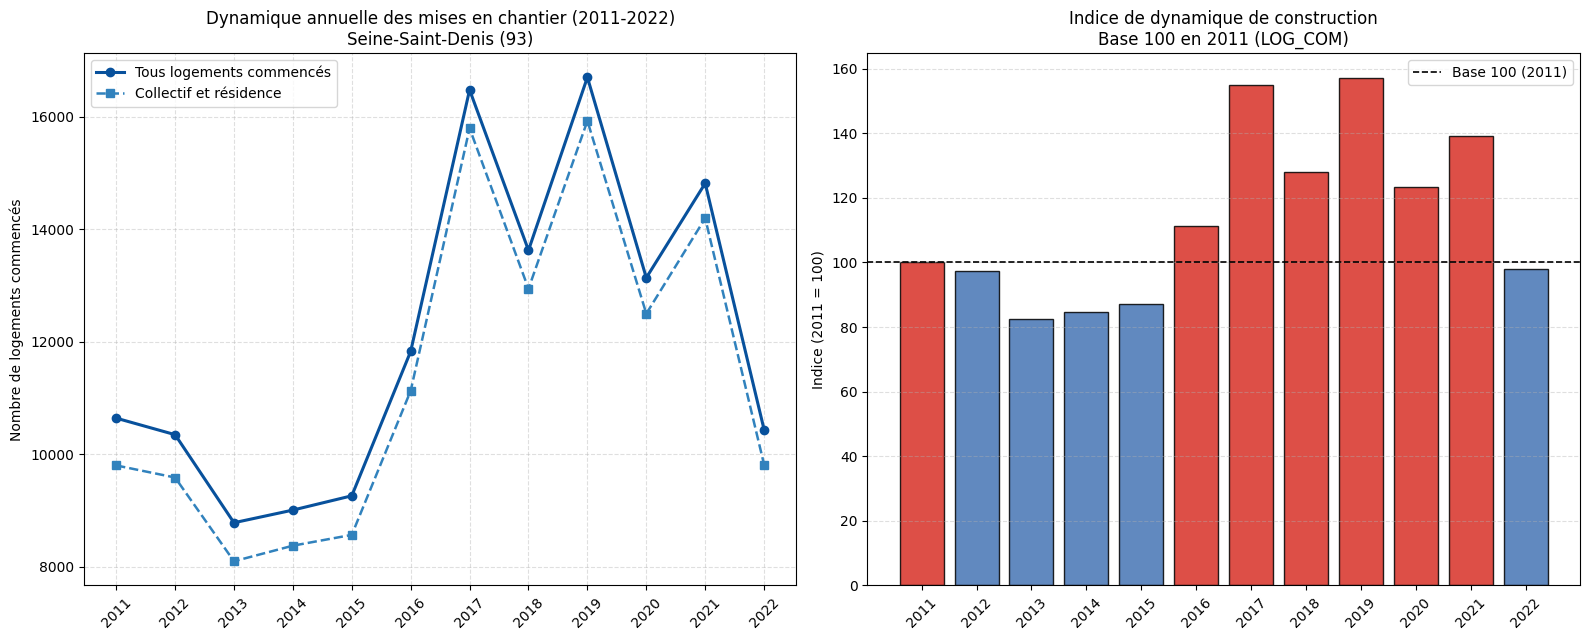

In [ ]:
DEPARTEMENT = "93"
ANNEES = range(2011, 2023)


def charger_sitadel(nom_fichier: str, departement: str = DEPARTEMENT) -> pd.DataFrame:
  # Logements commencés par année (lignes) et type de logement (colonnes).
  chemin = _trouver_fichier(nom_fichier, DOSSIER_PROJET)
  df = pd.read_csv(chemin, sep=";", encoding="utf-8-sig", low_memory=False)

  df["ANNEE"] = pd.to_numeric(df["ANNEE"], errors="coerce")
  df["LOG_COM"] = pd.to_numeric(df["LOG_COM"], errors="coerce")
  df["DEPARTEMENT_CODE"] = (
      df["DEPARTEMENT_CODE"].astype(str).str.strip().str.zfill(2)
  )

  df = df[
      (df["DEPARTEMENT_CODE"] == departement) & df["ANNEE"].between(2011, 2022)
  ]
  return df.pivot_table(
      index="ANNEE", columns="TYPE_LGT", values="LOG_COM", aggfunc="sum"
  )

sitadel = charger_sitadel("Donnees-mensuelles-departementales-Logements.2026-10.csv")

tous_log = sitadel["Tous Logements"]
collectif = sitadel["Collectif et Residence"]

indice_b100 = tous_log / tous_log.loc[2011] * 100
evol_pct = (tous_log.loc[2022] / tous_log.loc[2011] - 1) * 100

print(f"Logements commencés (93) - 2011 : {tous_log.loc[2011]:,.0f}")
print(f"Logements commencés (93) - 2022 : {tous_log.loc[2022]:,.0f}")
print(f"Évolution 2011 -> 2022         : {evol_pct:+.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

axes[0].plot(tous_log.index, tous_log, marker="o", linewidth=2.2,
             color="#08519c", label="Tous logements commencés")
axes[0].plot(collectif.index, collectif, marker="s", linewidth=1.8,
             linestyle="--", color="#3182bd", label="Collectif et résidence")
axes[0].set_title(
    "Dynamique annuelle des mises en chantier (2011-2022)\nSeine-Saint-Denis (93)",
    fontsize=12,
)
axes[0].set_ylabel("Nombre de logements commencés")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

couleurs = ["#d73027" if v >= 100 else "#4575b4" for v in indice_b100]
axes[1].bar(indice_b100.index, indice_b100, color=couleurs,
            edgecolor="black", alpha=0.85)
axes[1].axhline(100, color="black", linestyle="--", linewidth=1.2,
                label="Base 100 (2011)")
axes[1].set_title("Indice de dynamique de construction\nBase 100 en 2011 (LOG_COM)",
                  fontsize=12)
axes[1].set_ylabel("Indice (2011 = 100)")
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

for ax in axes:
  ax.set_xticks(list(ANNEES))
  ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Les mises en chantier suivent une trajectoire en trois temps. De 2011 à 2015, la construction est en retrait : elle passe d'environ 10 600 logements commencés à moins de 9 000 en 2013 (indice de 82), puis ne se redresse que faiblement. À partir de 2016, le rythme s'accélère nettement, avec des pics à environ 16 500 logements en 2017 (indice de 155) et 16 700 en 2019 (indice de 157), entrecoupés de creux en 2018 et 2020, ce dernier coïncidant vraisemblablement avec la crise sanitaire. En 2022, les mises en chantier retombent à environ 10 400 logements, soit un niveau proche de celui de 2011 (indice de 98).

La construction est massivement tirée par le collectif et les résidences, dont la courbe suit presque parfaitement celle de l'ensemble, ce qui est caractéristique d'un territoire dense et urbanisé. Le cycle 2016-2021 est cohérent avec les grands projets du Grand Paris et des Jeux olympiques de 2024, et compatible avec les mutations de Saint-Ouen-sur-Seine, mais il s'agit d'une hypothèse, car les données sont départementales.

Enfin, le retour de l'indice à environ 100 en 2022 ne signifie pas une absence de dynamique entre 2011 et 2022 : il marque la fin d'un pic de construction, et ces données ne permettent pas de dire si la baisse de 2022 est durable.

6. Évolution de la taille moyenne des ménages à Saint-Ouen-sur-Seine (2011-2022)

Nous partons des contours des IRIS de Saint-Ouen-sur-Seine déjà chargés et des bases INSEE « Couples, familles, ménages » de 2011 et 2022. Pour chaque millésime, la fonction charger_taille_menages lit le fichier Excel (skiprows=5), repère la colonne du code IRIS et la met sur 9 caractères. Nous convertissons ensuite en numérique le nombre de ménages (C{an}_MEN) et la population des ménages (C{an}_PMEN), puis calculons la taille moyenne en divisant la seconde par le premier, en remplaçant les zéros du dénominateur par NaN.

Nous fusionnons les deux années aux géométries des IRIS par merge(how="left") sur le code IRIS, puis calculons l'évolution en nombre de personnes par ménage (taille_2022 - taille_2011). Nous calculons également la taille moyenne de l'ensemble de la commune en divisant la somme des populations des ménages par la somme des ménages, ce qui donne une moyenne pondérée et non une simple moyenne des IRIS.

Nous traçons enfin trois cartes côte à côte, produites par une même boucle à partir d'une liste de paramètres. Les cartes de 2011 et 2022 utilisent la palette Purples avec des bornes communes, ce qui les rend directement comparables. La carte d'évolution utilise la palette divergente RdBu_r avec des bornes symétriques autour de zéro : le rouge indique des ménages plus grands, le bleu des ménages plus petits. Les IRIS sans valeur apparaissent en gris hachuré, et la fonction cadrer_carte ajuste l'emprise de chaque carte.

Taille moyenne Saint-Ouen 2011 : 2.16 pers./ménage
Taille moyenne Saint-Ouen 2022 : 2.17 pers./ménage


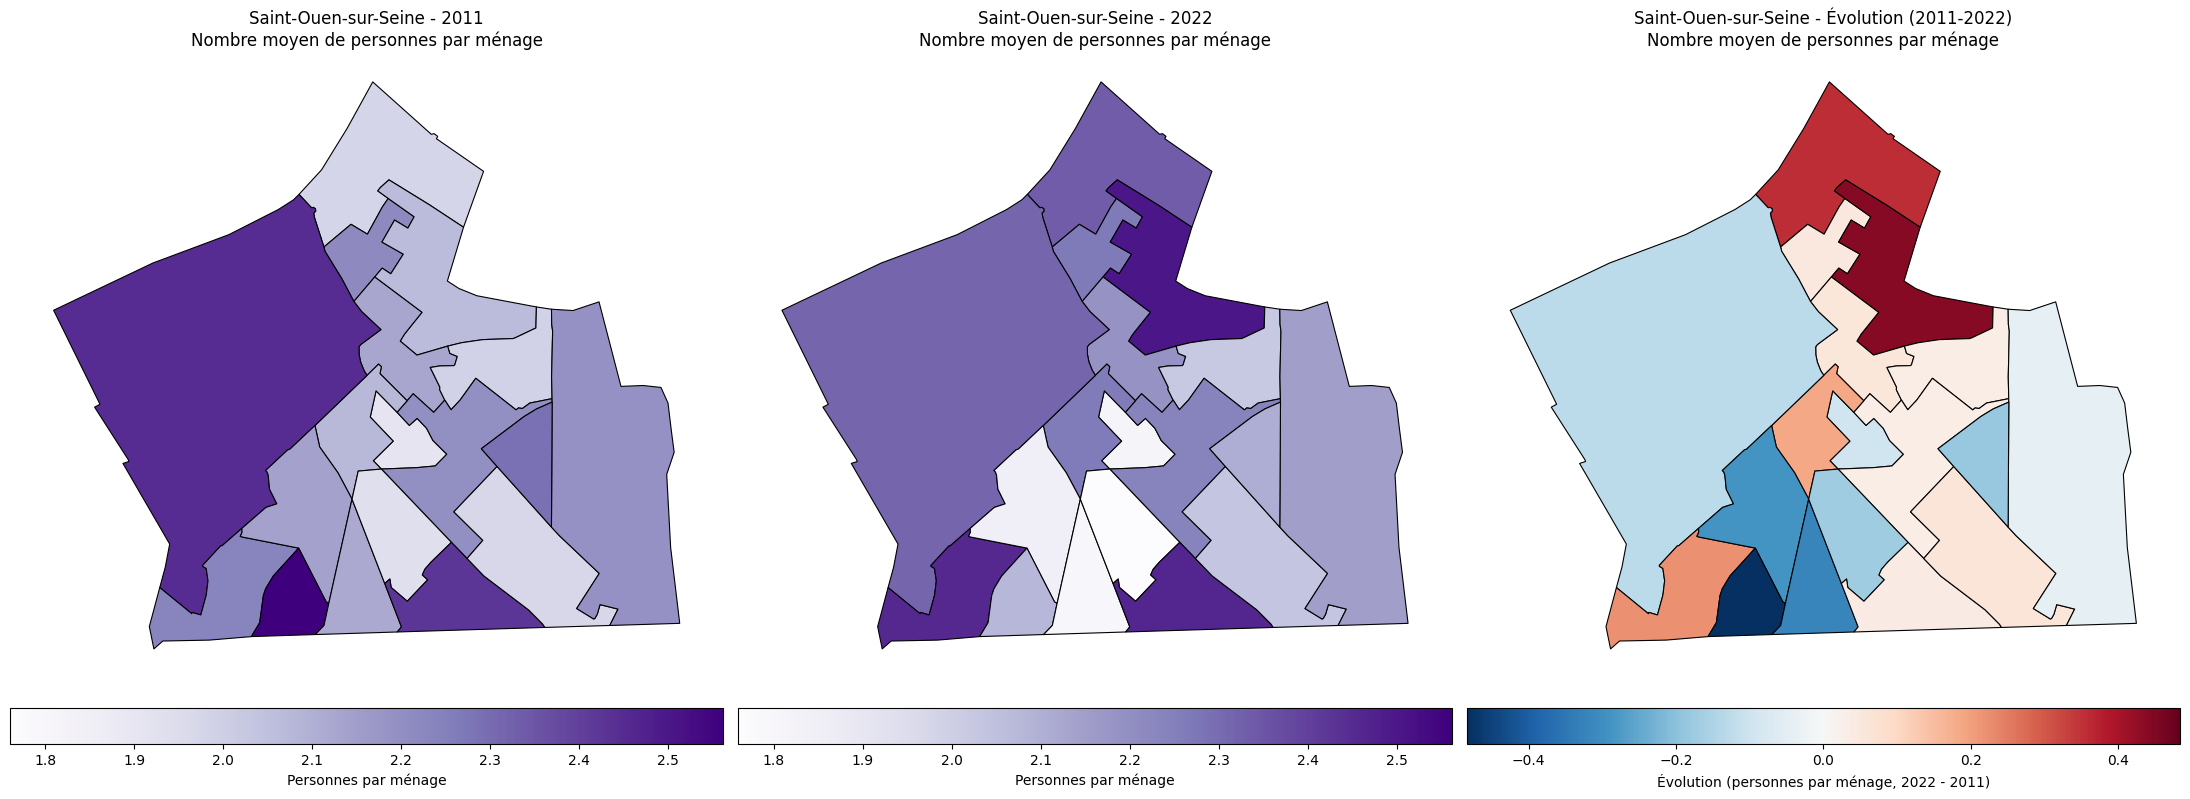

In [27]:
FICHIERS_CFM = {
    2011: "base-ic-couples-familles-menages-2011.xls",
    2022: "base-ic-couples-familles-menages-2022.xlsx",
}


def charger_taille_menages(nom_fichier: str, annee: int) -> pd.DataFrame:
  # Ménages, population des ménages et taille moyenne par IRIS.
  c = str(annee)[2:]
  df = pd.read_excel(_trouver_fichier(nom_fichier, DOSSIER_PROJET), skiprows=5)
  col_iris = next(
      (c_ for c_ in df.columns if "IRIS" in str(c_).upper() or "CODE" in str(c_).upper()),
      df.columns[0],
  )
  out = pd.DataFrame({
      COL_IRIS: df[col_iris].astype(str).str.split(".").str[0].str.strip().str.zfill(9),
      f"men_{annee}": pd.to_numeric(df[f"C{c}_MEN"], errors="coerce"),
      f"pmen_{annee}": pd.to_numeric(df[f"C{c}_PMEN"], errors="coerce"),
  })
  out[f"taille_{annee}"] = out[f"pmen_{annee}"] / out[f"men_{annee}"].replace(0, np.nan)
  return out


taille = st_ouen_iris[[COL_IRIS, "geometry"]]
for annee, fichier in FICHIERS_CFM.items():
  taille = taille.merge(charger_taille_menages(fichier, annee), on=COL_IRIS, how="left")

taille["evol_taille"] = taille["taille_2022"] - taille["taille_2011"]

for annee in FICHIERS_CFM:
  moy = taille[f"pmen_{annee}"].sum() / taille[f"men_{annee}"].sum()
  print(f"Taille moyenne Saint-Ouen {annee} : {moy:.2f} pers./ménage")


vmin_t = taille[["taille_2011", "taille_2022"]].min().min()
vmax_t = taille[["taille_2011", "taille_2022"]].max().max()
vmax_e = taille["evol_taille"].abs().max()

cartes = [
    ("taille_2011", "Purples", vmin_t, vmax_t, "Personnes par ménage",
     "2011\nNombre moyen de personnes par ménage"),
    ("taille_2022", "Purples", vmin_t, vmax_t, "Personnes par ménage",
     "2022\nNombre moyen de personnes par ménage"),
    ("evol_taille", "RdBu_r", -vmax_e, vmax_e,
     "Évolution (personnes par ménage, 2022 - 2011)",
     "Évolution (2011-2022)\nNombre moyen de personnes par ménage"),
]

fig, axes = plt.subplots(1, 3, figsize=(22, 8))
for ax, (col, cmap, vmin, vmax, label, titre) in zip(axes, cartes):
  taille.plot(
      ax=ax, column=col, cmap=cmap, vmin=vmin, vmax=vmax,
      edgecolor="black", linewidth=0.8, legend=True,
      missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
      legend_kwds={"label": label, "orientation": "horizontal", "pad": 0.04},
  )
  ax.set_title(f"Saint-Ouen-sur-Seine - {titre}", fontsize=12)
  cadrer_carte(ax, taille)

plt.tight_layout()
plt.show()

En 2011, la taille moyenne des ménages varie d'environ 1,8 à 2,5 personnes selon les IRIS. Les ménages les plus grands se concentrent dans le grand IRIS de l'ouest (autour de 2,4) et dans un petit IRIS du sud (plus de 2,5), tandis que les ménages les plus petits se trouvent au centre et dans la partie sud-est, avec des valeurs proches de 1,8 à 2,0. En 2022, l'amplitude reste du même ordre (de 1,8 à 2,5), mais la répartition change : l'IRIS de l'ouest se situe désormais autour de 2,2 à 2,3, et un IRIS du centre-nord passe à plus de 2,5.

La carte d'évolution montre des trajectoires opposées selon les secteurs, avec des variations comprises entre environ -0,5 et +0,5 personne par ménage. Le nord et le centre-nord connaissent les hausses les plus fortes (jusqu'à +0,5), de même qu'un IRIS du sud-ouest (autour de +0,3). À l'inverse, le grand IRIS de l'ouest recule légèrement (environ -0,1 à -0,2), et plusieurs IRIS du centre-sud enregistrent les baisses les plus marquées, jusqu'à -0,5 pour le plus touché. L'est de la commune reste globalement stable. Il n'y a donc pas de tendance uniforme à la baisse de la taille des ménages : le mouvement est très contrasté d'un quartier à l'autre.

Cette géographie est à rapprocher de celle de la part des familles monoparentales et nombreuses. Le nord et le centre-nord cumulent une hausse de cette part et un agrandissement des ménages, ce qui est cohérent avec un maintien, voire une concentration, de familles dans ces secteurs. À l'inverse, la baisse de la taille des ménages dans le centre-sud et l'ouest est compatible avec l'arrivée de ménages plus petits (personnes seules, couples sans enfant), profil souvent associé aux premières phases de gentrification. Cette lecture reste une hypothèse : une baisse de la taille moyenne peut aussi venir de la construction de logements neufs ou du desserrement des ménages déjà présents.

Enfin, le découpage des IRIS ayant changé entre 2011 et 2022, certains IRIS peuvent ne pas être appariés ou ne pas couvrir le même périmètre aux deux dates : la comparaison zone par zone doit donc être nuancée.